# Momentum del rango de apertura contra el VWAP de 24 h

**BTC perpetuo (Binance USDⓈ-M), velas de 5 minutos, sesión de contado de EE. UU.**

## La tesis

Los primeros 5 minutos de la sesión NYSE/CME como predictor del color de la vela diaria:

| | Regla |
|---|---|
| **Señal** | La primera vela de 5 min de la sesión (09:30→09:35 ET) |
| **Largo** | Vela alcista (cierre > apertura) **y** cierre **por encima** del VWAP de las últimas 24 h (288 velas de 5 min, **incluidas las overnight**) |
| **Corto** | Vela bajista **y** cierre **por debajo** de ese mismo VWAP |
| **Nada** | Cuando el color y el lado del ancla discrepan |
| **Entrada** | Al open de la vela siguiente (09:35 ET) |
| **Salida** | 15:45 ET del mismo día. Sin posición overnight |
| **Tamaño** | Unidades de riesgo normalizadas por volatilidad (N sizing) |

El mecanismo que se postula es **flujo de la sesión de contado**: si la apertura de la renta
variable estadounidense empuja al bitcoin, el primer impulso debería tener continuación, y el
VWAP de 24 h dice si ese impulso ocurre por encima o por debajo del precio medio al que el
contrato cambió de manos desde la apertura anterior.

## Lo que ya sabemos, y que condiciona este cuaderno

Este repositorio ha matado dos sistemas de reversión seguidos:

1. **Fade de ruptura Donchian 24/7** — el 56 % del bruto se lo comían las comisiones frente a
   un stop de 46 pb.
2. **Fade contra VWAP** — parecía tener edge, y el edge era **ceguera al stop overnight**: al
   evaluar los stops sobre el camino 24/7 completo, desaparecía.

De ahí tres decisiones de diseño que NO son opcionales aquí:

- Los costes se miden, no se asumen: se reporta **el coste como fracción del bruto** en cada
  tabla de resultados, no solo el neto.
- El funding es el **histórico real** por símbolo, no un supuesto.
- Esta estrategia es **estructuralmente inmune** al fallo que mató a la segunda: cierra a las
  15:45 ET, así que nunca hay una orden en reposo cruzando la noche. Se pasa `path=` el marco
  24/7 de todas formas, y se **comprueba** que no cambia nada (§9).

## Sesgos declarados antes de mirar ningún resultado

| Sesgo | Cómo entra aquí | Qué se hace |
|---|---|---|
| **Look-ahead** | El ancla y la N se miden sobre el marco 24/7 y se alinean a barras de sesión | `assert_no_lookahead` sobre las tres series + test de truncamiento en `opening_range_test.py` |
| **Optimización** | Cada barrido cuenta como ensayo | `N_TRIALS` se acumula explícitamente y alimenta el DSR |
| **Selección de símbolo** | BTC es el objetivo del repo | Se declara BTCUSDT como *flagship* ANTES de mirar resultados; el resto es confirmación |
| **Supervivencia** | El universo es de hoy | Universo fijo y pequeño; se reporta el inicio real de cada serie |
| **Muestra corta** | QQQUSDT cotiza desde 2026 | Se usa solo como **control descriptivo** y se excluye de WFO/DSR/PBO |
| **Festivos** | `restrict_to_session` no filtra festivos del NYSE | ~9 sesiones/año residuales; se cuantifica en §5 |

## 1. Setup

In [1]:
import sys, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")
pd.set_option("display.width", 200, "display.max_columns", 60)

plt.rcParams.update({
    "figure.figsize": (14, 6), "axes.grid": True, "grid.alpha": 0.25,
    "font.size": 10, "axes.spines.top": False, "axes.spines.right": False,
})

ROOT = Path.cwd()
while not (ROOT / "pyproject.toml").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
OUT = ROOT / "output"; OUT.mkdir(exist_ok=True)

from qsCrypto.backtest.binance_data import (
    fetch_klines_history, fetch_funding_history, restrict_to_session, RTH_TZ,
)
from qsCrypto.backtest.engine import (
    BacktestParams, OpeningRangeVwapRule, run_backtest, run_portfolio_backtest,
)
from qsCrypto.strategy.strategy import (
    compute_vwap, rolling_range_n, opening_range_signal,
)
from qsCrypto.backtest.skill_stats.bias_audit import (
    assert_no_lookahead, pnl_concentration, effective_bets,
    cost_sensitivity, mc_bootstrap_trades, equity_metrics,
)
from qsCrypto.backtest.skill_stats.purged_cv import walk_forward_folds
from qsCrypto.backtest.skill_stats.stats_tests import (
    deflated_sharpe_ratio, fold_ttest, pbo_cscv,
)
from qsCrypto.portfolio.mae import mae_star, win_prob_curve, edge_ratio

print(f"ROOT : {ROOT}")
print("Setup OK")

ROOT : /Users/diegoochoa/Projects/Intraday_MR_BTC
Setup OK


### 1.1 Parámetros y por qué

**El stop.** La especificación no menciona stop: dice sizing por N y salida a las 15:45. Se
respeta literalmente. `stop_n=1.0` fija la **unidad de riesgo** (1R = 1N: es lo que dimensiona
y lo que normaliza `r_multiple`) y `mae_stop_n=inf` deja que la posición **solo** se cierre en
el cierre de sesión. La ventaja no es filosófica: con un stop real, la distribución de MAE
queda truncada en el stop y ya no se puede calibrar un stop a partir de ella. Sin stop, la
excursión adversa se observa entera y §10 puede preguntarse *si* merece la pena ponerlo.

**La N.** Con velas de 5 minutos, `compute_n(period=288)` NO es la volatilidad de 24 h: es el
rango medio de *una vela de 5 minutos* suavizado sobre un día (~104 $ con BTC a 46 000 $),
mientras que el recorrido de 24 h son ~2 055 $ y el de una sesión ~1 370 $. Dimensionar con
ella infradimensiona el riesgo ~13x: al primer intento, R salía en ±20 y la cuenta se partía
por la mitad con "1 % de riesgo". Se usa `rolling_range_n`: el rango de las últimas 288 velas,
que mide el horizonte de la posición y sale del **mismo búfer de 288 velas** que ya necesita
el ancla — así el motor en vivo no necesita una serie diaria aparte.

**Sin pirámide.** `max_units=1`: la especificación no menciona añadir unidades. La escalera
Turtle de ½N existe en el motor y queda para el barrido, no para la línea base.

In [9]:
SESSION_ONLY = True
INTERVAL     = "5m"
START        = "2026-01-01"
END          = "2026-09-23 00:00:00"      # ancla explícita, no "ahora"

# La sesión: 09:30 -> 15:45 ET. La ventana es semiabierta, así que la última
# barra es la que ABRE a las 15:40 y CIERRA a las 15:45 — exactamente donde la
# especificación quiere estar plano.
SESS_START, SESS_END = "09:30", "15:59"
BARS_PER_SESSION = 78                      # 6 h 15 min en velas de 5 min

FLAGSHIP = "BTCUSDT"                       # declarado ANTES de ver resultados
CRYPTO   = ["BTCUSDT", "ETHUSDT", "SOLUSDT"]
CONTROL  = "QQQUSDT"                       # proxy Nasdaq: control descriptivo
PILOT    = CRYPTO + [CONTROL]

OR_BARS   = 1        # el rango de apertura son los primeros 5 minutos
VWAP_BARS = 12      # 24 h de velas de 5 min, incluidas las overnight
N_WINDOW  = 14      # mismo horizonte para la N
N_MODE    = "roll24h"

BASE = BacktestParams(
    stop_n=1.0,                  # 1R = 1N: sizing y r_multiple
    mae_stop_n=float("inf"),     # sin stop real: se sale en el cierre de sesión
    max_units=1,                 # sin escalera Turtle en la línea base
    max_hold_bars=10 ** 9,       # la barrera vertical no debe adelantarse al cierre
    tp_mode="take_n", take_n=1e9,  # sin objetivo
    flat_at_session_end=True,    # <- la salida de las 15:45
    risk_per_trade=0.01, equity0=10_000.0,
    fee_bps=0.0002, slip_bps=0.0001,
    dd_from_peak=True,
    atr_period=VWAP_BARS,        # solo afecta al calentamiento del libro
)

def make_rule(**kw):
    """La regla de la línea base, con overrides para los barridos."""
    cfg = dict(or_bars=OR_BARS, vwap_bars=VWAP_BARS, n_window=N_WINDOW,
               n_mode=N_MODE, allow_short=True)
    cfg.update(kw)
    return OpeningRangeVwapRule(**cfg)

N_TRIALS = 0      # se va acumulando en cada barrido; alimenta el DSR
print("Configuración fijada. Flagship:", FLAGSHIP)

Configuración fijada. Flagship: BTCUSDT


### 1.2 Costes

In [10]:
rt_bps = 2 * (BASE.fee_bps + BASE.slip_bps) * 1e4
print(f"Comisión taker   : {BASE.fee_bps*1e4:.1f} pb por lado")
print(f"Deslizamiento    : {BASE.slip_bps*1e4:.1f} pb por lado")
print(f"Round trip       : {rt_bps:.1f} pb de nocional")
print(f"Funding          : histórico real por símbolo, cada 8 h")
print(f"Apalancamiento   : <= {BASE.max_gross_lev:.0f}x bruto")
print()
print("Con una sola operación por sesión y ~6 h de exposición, la posición cruza")
print("como mucho una liquidación de funding. Lo que decide aquí es el round trip")
print("frente al recorrido de la sesión: §9 lo mide como fracción del bruto.")

Comisión taker   : 2.0 pb por lado
Deslizamiento    : 1.0 pb por lado
Round trip       : 6.0 pb de nocional
Funding          : histórico real por símbolo, cada 8 h
Apalancamiento   : <= 10x bruto

Con una sola operación por sesión y ~6 h de exposición, la posición cruza
como mucho una liquidación de funding. Lo que decide aquí es el round trip
frente al recorrido de la sesión: §9 lo mide como fracción del bruto.


## 2. Datos

El marco **24/7 sin filtrar** (`CTX`) no es un extra: es donde viven el ancla de 24 h y la N.
Calcularlas sobre la serie de sesión daría un VWAP de las últimas 288 barras *de sesión* —
casi cuatro días de solo horario regular — que no es lo que dice la estrategia, y además se
saltaría justo el tramo overnight que el ancla pretende resumir.

In [11]:
CTX, FUNDING, DATA = {}, {}, {}
for s in PILOT:
    CTX[s] = fetch_klines_history(s, interval=INTERVAL, start=START, end=END)
    FUNDING[s] = fetch_funding_history(s, start=START, end=END)
    DATA[s] = restrict_to_session(CTX[s], start=SESS_START, end=SESS_END)

INV = pd.DataFrame([{
    "symbol": s,
    "barras_24_7": len(CTX[s]),
    "barras_sesion": len(DATA[s]),
    "sesiones": DATA[s].index.normalize().nunique(),
    "inicio": DATA[s].index[0], "fin": DATA[s].index[-1],
    "años": round((DATA[s].index[-1] - DATA[s].index[0]).days / 365.25, 2),
} for s in PILOT])
display(INV)

# Toda sesión debe tener sus 75 barras: una sesión corta (medio día de fiesta,
# hueco de datos) no tiene el mismo rango de apertura ni el mismo cierre.
for s in PILOT:
    sizes = DATA[s].groupby(DATA[s].index.date).size()
    short = sizes[sizes != BARS_PER_SESSION]
    print(f"{s:9s} sesiones={len(sizes):5d}  incompletas={len(short):3d}"
          f"  ({100*len(short)/len(sizes):.1f}%)")

# `df` DEBE ser un subconjunto exacto de `ctx`: la regla lo exige para poder
# reindexar el ancla sin relleno.
for s in PILOT:
    assert DATA[s].index.isin(CTX[s].index).all(), s
    assert DATA[s].equals(restrict_to_session(DATA[s], start=SESS_START, end=SESS_END)), s
print("\nFiltro de sesión idempotente y contenido en el marco 24/7: OK")

FREQ = int(round(INV.set_index("symbol").loc[FLAGSHIP, "sesiones"]
                 / INV.set_index("symbol").loc[FLAGSHIP, "años"]))
print(f"FREQ (sesiones/año) = {FREQ}  <- el Sharpe de aquí NO es comparable con")
print("   los cuadernos de 30 min 24/7, que anualizan con 365 días de barras.")

,symbol,barras_24_7,barras_sesion,sesiones,inicio,fin,años
0,BTCUSDT,76321,14742,189,2026-01-01 14:30:00,2026-09-22 19:55:00,0.72
1,ETHUSDT,76321,14742,189,2026-01-01 14:30:00,2026-09-22 19:55:00,0.72
2,SOLUSDT,76321,14742,189,2026-01-01 14:30:00,2026-09-22 19:55:00,0.72
3,QQQUSDT,48799,9516,122,2026-04-06 13:30:00,2026-09-22 19:55:00,0.46


BTCUSDT   sesiones=  189  incompletas=  0  (0.0%)
ETHUSDT   sesiones=  189  incompletas=  0  (0.0%)
SOLUSDT   sesiones=  189  incompletas=  0  (0.0%)
QQQUSDT   sesiones=  122  incompletas=  0  (0.0%)

Filtro de sesión idempotente y contenido en el marco 24/7: OK
FREQ (sesiones/año) = 262  <- el Sharpe de aquí NO es comparable con
   los cuadernos de 30 min 24/7, que anualizan con 365 días de barras.


**Sobre QQQUSDT.** Su serie empieza mucho después que el resto. Es el control que hace
interpretable un resultado nulo en BTC: si la tesis es flujo real de la sesión de contado, el
efecto tiene que verse **más fuerte** en el proxy del Nasdaq que en el bitcoin. Pero con tan
pocas sesiones no admite walk-forward ni DSR, así que entra como **descriptivo** y se excluye
de §11-§13. Se comprueba explícitamente abajo en vez de confiar en la memoria.

In [12]:
MIN_YEARS_WFO = 2.0
inv = INV.set_index("symbol")
WFO_OK = [s for s in PILOT if inv.loc[s, "años"] >= MIN_YEARS_WFO]
EXCLUDED = [s for s in PILOT if s not in WFO_OK]
print("Aptos para WFO/DSR/PBO :", WFO_OK)
print("Solo descriptivos      :", EXCLUDED,
      "" if not EXCLUDED else f"(< {MIN_YEARS_WFO} años de muestra)")
assert FLAGSHIP in WFO_OK, "el flagship no tiene muestra suficiente"

Aptos para WFO/DSR/PBO : []
Solo descriptivos      : ['BTCUSDT', 'ETHUSDT', 'SOLUSDT', 'QQQUSDT'] (< 2.0 años de muestra)


AssertionError: el flagship no tiene muestra suficiente

## 3. Tests de look-ahead

Las tres series que entran en la decisión, truncando la muestra en instantes aleatorios y
comprobando que el valor en el último punto no cambia. El tercero es el que importa: es el
único sitio donde la alineación entre el marco 24/7 y las barras de sesión podría colar
información del futuro.

In [13]:
ctx0 = CTX[FLAGSHIP]

def f_vwap(d):
    return pd.Series(compute_vwap(d["high"], d["low"], d["close"], d["volume"],
                                  mode="rolling", bars=VWAP_BARS, index=d.index),
                     index=d.index)

def f_n(d):
    return pd.Series(rolling_range_n(d["high"], d["low"], window=N_WINDOW),
                     index=d.index)

LA = {}
LA["vwap_24h"] = assert_no_lookahead(f_vwap, ctx0, n_checks=30, min_bars=VWAP_BARS * 2)
LA["n_24h"]    = assert_no_lookahead(f_n,    ctx0, n_checks=30, min_bars=N_WINDOW * 2)
print("VWAP de 24 h y N de 24 h sobre el marco 24/7: sin look-ahead")

VWAP de 24 h y N de 24 h sobre el marco 24/7: sin look-ahead


In [14]:
# El tercero, y el que de verdad puede estar mal: el ancla YA ALINEADA a las
# barras de sesión. Se reconstruye la regla sobre una muestra truncada y se
# compara con la regla sobre la muestra completa, en la misma barra de señal.
_, tr_full = run_backtest(DATA[FLAGSHIP], BASE, rule=make_rule(), ctx=ctx0)
R_FULL = tr_full.attrs["rule"]

sig_idx = np.flatnonzero(np.asarray(R_FULL.signal_bar)
                         & np.isfinite(np.asarray(R_FULL.anchor, dtype=float)))
rng = np.random.default_rng(11)
checks = []
for i in rng.choice(sig_idx[len(sig_idx)//4:], size=12, replace=False):
    t = DATA[FLAGSHIP].index[int(i)]
    _, tr_cut = run_backtest(DATA[FLAGSHIP].loc[:t], BASE, rule=make_rule(),
                             ctx=ctx0.loc[:t])
    rc = tr_cut.attrs["rule"]
    checks.append({
        "t": t,
        "anchor_full": R_FULL.anchor[int(i)], "anchor_trunc": rc.anchor[-1],
        "n_full": R_FULL.n_ctx[int(i)], "n_trunc": rc.n_ctx[-1],
    })
CH = pd.DataFrame(checks)
CH["ok"] = (np.isclose(CH["anchor_full"], CH["anchor_trunc"], rtol=1e-10)
            & np.isclose(CH["n_full"], CH["n_trunc"], rtol=1e-10))
display(CH)
LOOKAHEAD_OK = bool(CH["ok"].all()) and len(CH) == 12
assert LOOKAHEAD_OK, "el ancla alineada cambia al truncar: HAY look-ahead"
print("\nAncla y N alineadas a la sesión: idénticas al truncar. Sin look-ahead.")

,t,anchor_full,anchor_trunc,n_full,n_trunc,ok
0,2026-08-04 13:30:00,63916.709190,63916.709190,268.7,268.7,True
1,2026-05-26 13:30:00,76890.212569,76890.212569,475.5,475.5,True
2,2026-06-10 13:30:00,61620.851601,61620.851601,885.6,885.6,True
3,2026-06-26 13:30:00,59041.155149,59041.155149,1610.4,1610.4,True
4,2026-06-09 13:30:00,62427.397191,62427.397191,488.5,488.5,True
5,2026-04-06 13:30:00,69396.386719,69396.386719,238.4,238.4,True
6,2026-03-12 13:30:00,70236.429060,70236.429060,682.8,682.8,True
7,2026-09-08 13:30:00,78280.872674,78280.872674,468.0,468.0,True
8,2026-03-31 13:30:00,66789.774728,66789.774728,365.0,365.0,True
9,2026-06-30 13:30:00,58504.232461,58504.232461,699.7,699.7,True



Ancla y N alineadas a la sesión: idénticas al truncar. Sin look-ahead.


Diferencia relativa entre el ancla 24/7 y la de solo sesión:
  mediana 0.00%   p90 0.08%   max 6.21%


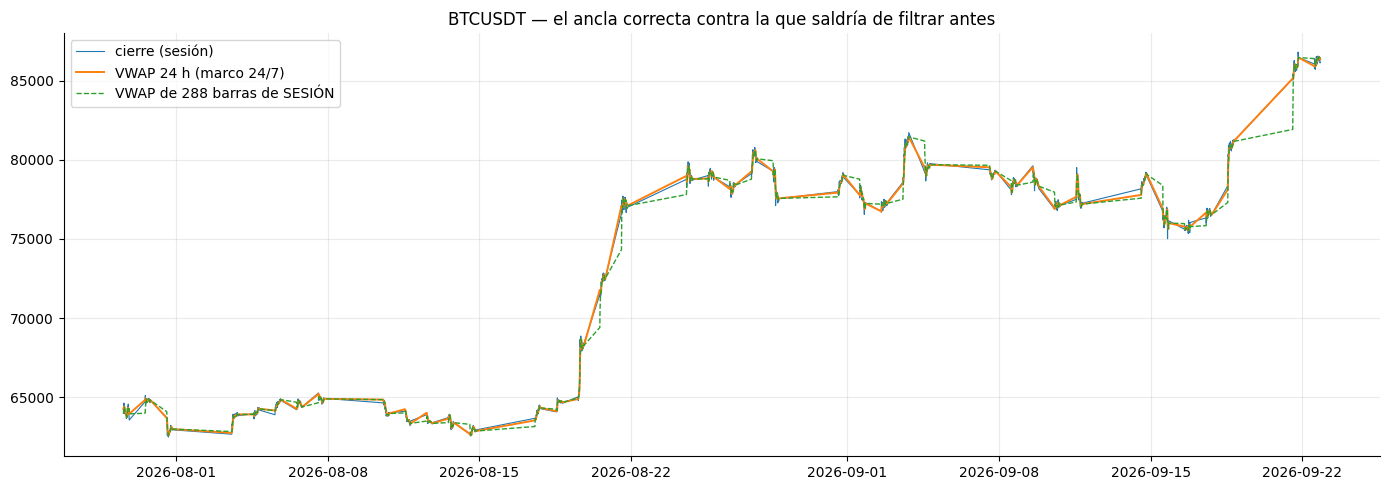

In [15]:
# Y la comprobación que justifica todo el aparato de `ctx`: el ancla de 24 h y
# la que saldría de las barras de sesión NO son la misma serie. Si empataran,
# el marco 24/7 sobraría.
anchor_ctx = pd.Series(R_FULL.anchor, index=DATA[FLAGSHIP].index).dropna()
_, tr_sess = run_backtest(DATA[FLAGSHIP], BASE, rule=make_rule(), ctx=DATA[FLAGSHIP])
anchor_sess = pd.Series(tr_sess.attrs["rule"].anchor,
                        index=DATA[FLAGSHIP].index).dropna()
common = anchor_ctx.index.intersection(anchor_sess.index)
rel = ((anchor_ctx[common] - anchor_sess[common]).abs() / anchor_ctx[common])
print(f"Diferencia relativa entre el ancla 24/7 y la de solo sesión:")
print(f"  mediana {rel.median()*100:.2f}%   p90 {rel.quantile(0.9)*100:.2f}%"
      f"   max {rel.max()*100:.2f}%")

fig, ax = plt.subplots(figsize=(14, 5))
sl = slice(-BARS_PER_SESSION * 40, None)
ax.plot(DATA[FLAGSHIP]["close"].iloc[sl], lw=0.8, label="cierre (sesión)")
ax.plot(anchor_ctx.iloc[sl], lw=1.4, label="VWAP 24 h (marco 24/7)")
ax.plot(anchor_sess.iloc[sl], lw=1.0, ls="--", label="VWAP de 288 barras de SESIÓN")
ax.set_title(f"{FLAGSHIP} — el ancla correcta contra la que saldría de filtrar antes")
ax.legend(); plt.tight_layout(); plt.show()

## 4. Anatomía de la señal — antes de ningún P&L

Lo que se mira aquí no depende de la ejecución ni de los costes: es la tasa base que la
estrategia está afirmando. Si el cierre de la sesión no cae del lado de la señal más del 50 %
de las veces, no hay nada que ejecutar y el resto del cuaderno solo mediría fricción.

In [16]:
def signal_table(sym):
    """Una fila por sesión con la señal y lo que hizo la sesión después."""
    df, ctx = DATA[sym], CTX[sym]
    _, tr = run_backtest(df, BASE, rule=make_rule(), ctx=ctx)
    r = tr.attrs["rule"]
    sig = np.flatnonzero(np.asarray(r.signal_bar))
    rows = []
    closes = df["close"].to_numpy()
    for i in sig:
        i = int(i)
        day = df.index[i].date()
        sess = df[df.index.date == day]
        if len(sess) != BARS_PER_SESSION:
            continue
        o, c = r.or_open[i], closes[i]
        a, n = r.anchor[i], r.n_ctx[i]
        if not np.isfinite([o, c, a, n]).all():
            continue
        side = opening_range_signal(o, c, a, n)
        entry = sess["open"].iloc[OR_BARS]        # el open donde se ejecutaría
        rows.append({
            "day": day, "or_open": o, "or_close": c, "anchor": a, "n": n,
            "body_n": (c - o) / n,
            "color": 1 if c > o else (-1 if c < o else 0),
            "vwap_side": 1 if c > a else (-1 if c < a else 0),
            "side": 0 if side is None else side,
            "entry": entry, "sess_close": sess["close"].iloc[-1],
            "fwd_n": (sess["close"].iloc[-1] - entry) / n,
        })
    return pd.DataFrame(rows)

SIG = {s: signal_table(s) for s in PILOT}
rows = []
for s in PILOT:
    t = SIG[s]
    traded = t[t["side"] != 0]
    agree = (t["color"] == t["vwap_side"]) & (t["color"] != 0)
    hit = np.sign(traded["fwd_n"]) == traded["side"]
    rows.append({
        "symbol": s, "sesiones": len(t),
        "acuerdo %": 100 * agree.mean(),
        "señales": len(traded),
        "largos %": 100 * (traded["side"] > 0).mean(),
        "acierto %": 100 * hit.mean(),
        "fwd_n medio (con señal)": (traded["fwd_n"] * traded["side"]).mean(),
        "fwd_n mediano": (traded["fwd_n"] * traded["side"]).median(),
        "|cuerpo| mediano (N)": t["body_n"].abs().median(),
    })
ANAT = pd.DataFrame(rows).round(3)
display(ANAT)
print("\n'acierto %' = el cierre de la sesión cae del lado de la señal.")
print("Es la tasa base BRUTA, sin costes: 50 % significa que no hay nada.")

,symbol,sesiones,acuerdo %,señales,largos %,acierto %,fwd_n medio (con señal),fwd_n mediano,|cuerpo| mediano (N)
0,BTCUSDT,189,79.365,150,44.667,47.333,-0.063,-0.105,0.217
1,ETHUSDT,189,81.481,154,46.753,44.156,-0.213,-0.115,0.203
2,SOLUSDT,189,77.249,146,50.000,48.630,-0.143,-0.038,0.196
3,QQQUSDT,121,85.950,104,47.115,55.769,0.208,0.185,0.340



'acierto %' = el cierre de la sesión cae del lado de la señal.
Es la tasa base BRUTA, sin costes: 50 % significa que no hay nada.


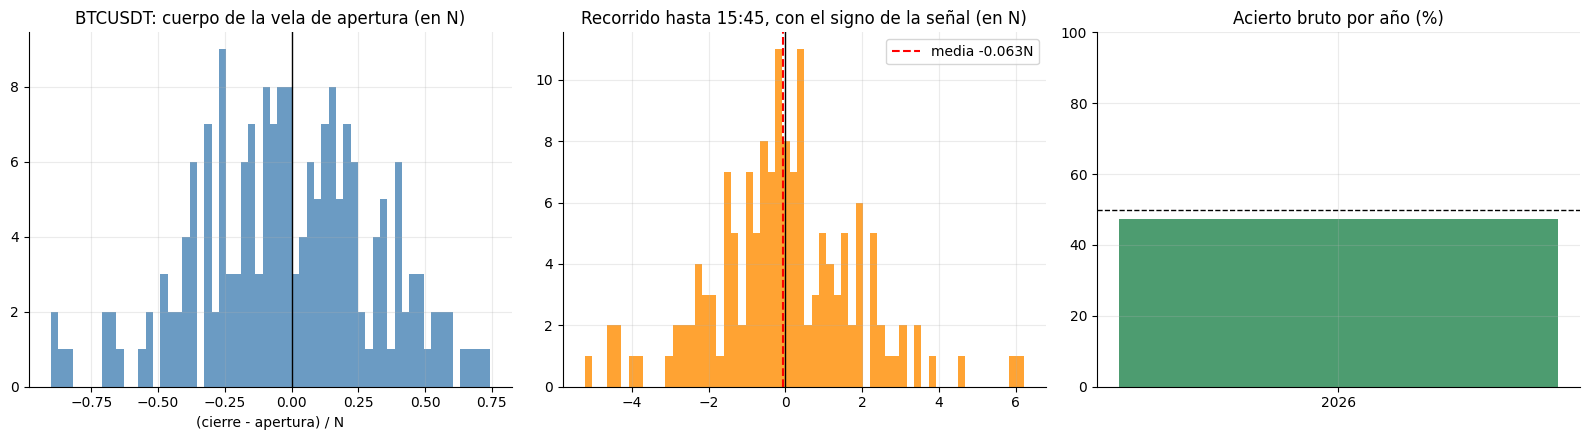

Tabla de contingencia color x lado del VWAP (flagship):


lado VWAP,-1,1
color vela,,
-1,83,17
1,22,67


In [17]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
t = SIG[FLAGSHIP]; traded = t[t["side"] != 0]

axes[0].hist(t["body_n"], bins=60, color="steelblue", alpha=.8)
axes[0].axvline(0, color="k", lw=1)
axes[0].set_title(f"{FLAGSHIP}: cuerpo de la vela de apertura (en N)")
axes[0].set_xlabel("(cierre - apertura) / N")

signed = traded["fwd_n"] * traded["side"]
axes[1].hist(signed, bins=60, color="darkorange", alpha=.8)
axes[1].axvline(0, color="k", lw=1)
axes[1].axvline(signed.mean(), color="red", ls="--",
                label=f"media {signed.mean():+.3f}N")
axes[1].set_title("Recorrido hasta 15:45, con el signo de la señal (en N)")
axes[1].legend()

by_year = traded.assign(y=pd.to_datetime(traded["day"]).dt.year)
acc = by_year.groupby("y").apply(
    lambda g: 100 * (np.sign(g["fwd_n"]) == g["side"]).mean())
axes[2].bar(acc.index.astype(str), acc.values, color="seagreen", alpha=.85)
axes[2].axhline(50, color="k", ls="--", lw=1)
axes[2].set_title("Acierto bruto por año (%)"); axes[2].set_ylim(0, 100)
plt.tight_layout(); plt.show()

print("Tabla de contingencia color x lado del VWAP (flagship):")
display(pd.crosstab(t["color"], t["vwap_side"], rownames=["color vela"],
                    colnames=["lado VWAP"]))

## 5. Línea base por símbolo

In [18]:
def metrics_row(sym, ec, tr, label):
    m = equity_metrics(ec, tr, freq=FREQ)
    gross_r = tr["r_multiple"] + tr["fees"] / (BASE.stop_n * tr["n"]
                                               * tr["notional0"] / tr["entry0"])
    coste_frac = (tr["fees"].sum() / tr["pnl"].abs().sum()
                  if len(tr) else np.nan)
    return {
        "symbol": sym, "sistema": label,
        "Retorno total": m["Retorno total"], "CAGR": m["CAGR"],
        "Sharpe": m["Sharpe"], "Sortino": m["Sortino"], "Max DD": m["Max DD"],
        "Calmar": m["Calmar"], "trades": len(tr),
        "win %": 100 * (tr["pnl"] > 0).mean() if len(tr) else np.nan,
        "R medio": tr["r_multiple"].mean() if len(tr) else np.nan,
        "R bruto medio": gross_r.mean() if len(tr) else np.nan,
        "coste / |P&L|": coste_frac,
        "payoff": (tr.loc[tr.pnl > 0, "pnl"].mean()
                   / abs(tr.loc[tr.pnl < 0, "pnl"].mean())) if len(tr) else np.nan,
    }

RESULTS, rows = {}, []
for s in PILOT:
    ec, tr = run_backtest(DATA[s], BASE, funding=FUNDING[s], rule=make_rule(),
                          ctx=CTX[s], path=CTX[s])
    RESULTS[s] = (ec, tr)
    rows.append(metrics_row(s, ec, tr, "línea base"))
BASE_TABLE = pd.DataFrame(rows).round(4)
display(BASE_TABLE)
print("rechazos (sesiones sin señal):",
      {s: RESULTS[s][1].attrs["rejected"] for s in PILOT})

,symbol,sistema,Retorno total,CAGR,Sharpe,Sortino,Max DD,Calmar,trades,win %,R medio,R bruto medio,coste / |P&L|,payoff
0,BTCUSDT,línea base,-0.1699,-0.2271,-7.8148,-8.9992,-0.3171,-0.7160,149,46.3087,-0.1444,-0.0905,0.0359,0.9447
1,ETHUSDT,línea base,-0.3083,-0.3995,-15.2142,-17.9258,-0.3674,-1.0873,153,42.4837,-0.2743,-0.2336,0.0279,0.8554
2,SOLUSDT,línea base,-0.2277,-0.3005,-12.4521,-14.4506,-0.3735,-0.8047,145,47.5862,-0.2046,-0.1667,0.0250,0.7769
3,QQQUSDT,línea base,0.0412,0.0911,2.7627,3.4633,-0.1674,0.5443,103,53.3981,0.0556,0.1509,0.0676,0.9090


rechazos (sesiones sin señal): {'BTCUSDT': {'desacuerdo': 39}, 'ETHUSDT': {'desacuerdo': 35}, 'SOLUSDT': {'desacuerdo': 43}, 'QQQUSDT': {'sin_n': 1, 'desacuerdo': 17}}


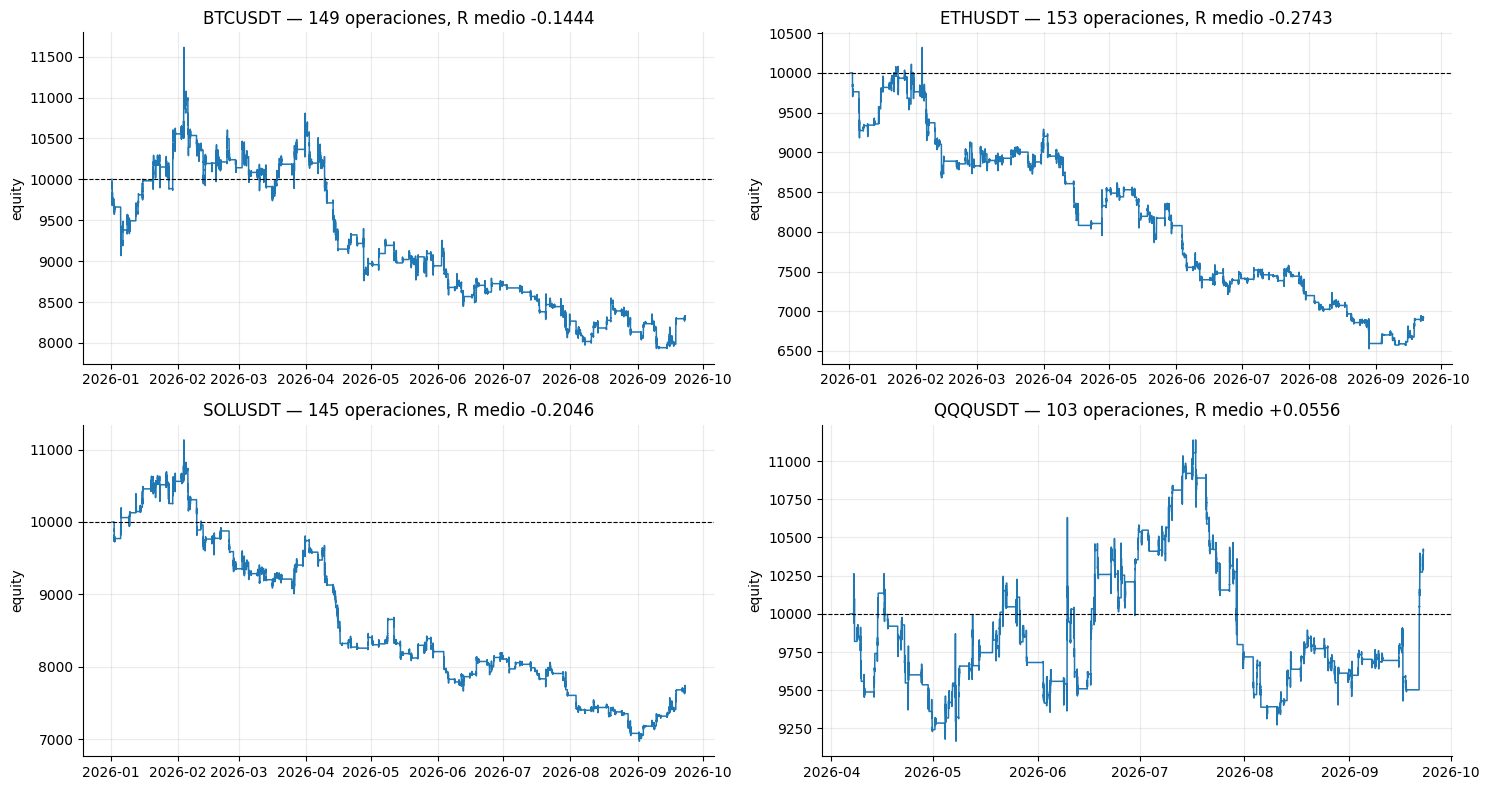

In [19]:
fig, axes = plt.subplots(2, 2, figsize=(15, 8))
for ax, s in zip(axes.ravel(), PILOT):
    ec, tr = RESULTS[s]
    ax.plot(ec.index, ec.values, lw=1.1)
    ax.axhline(BASE.equity0, color="k", ls="--", lw=.8)
    ax.set_title(f"{s} — {len(tr)} operaciones, "
                 f"R medio {tr['r_multiple'].mean():+.4f}")
    ax.set_ylabel("equity")
plt.tight_layout(); plt.show()

### 5.1 ¿Dónde se va el bruto?

La pregunta que mató a los dos sistemas anteriores. `R bruto` devuelve las comisiones a la
operación: la diferencia con `R` neto es la fricción, y aquí se ve en unidades de riesgo, no
en porcentaje del nocional.

In [20]:
rows = []
for s in PILOT:
    ec, tr = RESULTS[s]
    if not len(tr):
        continue
    qty0 = tr["notional0"] / tr["entry0"]
    r_unit = BASE.stop_n * tr["n"] * qty0
    fee_r = (tr["fees"] / r_unit)
    slip_r = (tr["slip_paid"] / r_unit)
    fund_r = (tr["funding_paid"] / r_unit)
    gross = tr["r_multiple"] + fee_r + slip_r - fund_r
    rows.append({
        "symbol": s,
        "R bruto medio": gross.mean(),
        "- comisiones (R)": -fee_r.mean(),
        "- deslizamiento (R)": -slip_r.mean(),
        "+/- funding (R)": fund_r.mean(),
        "= R neto medio": tr["r_multiple"].mean(),
        "fricción / |bruto|": (fee_r.mean() + slip_r.mean()) / abs(gross.mean())
        if gross.mean() != 0 else np.nan,
    })
COSTES = pd.DataFrame(rows).round(4)
display(COSTES)
print("Si 'fricción / |bruto|' se acerca a 1, el sistema opera para pagar comisiones.")
print("Referencia: el fade Donchian 24/7 estaba en ~0.56.")

,symbol,R bruto medio,- comisiones (R),- deslizamiento (R),+/- funding (R),= R neto medio,fricción / |bruto|
0,BTCUSDT,-0.0647,-0.0539,-0.0270,0.0011,-0.1444,1.2509
1,ETHUSDT,-0.2131,-0.0406,-0.0203,-0.0002,-0.2743,0.2858
2,SOLUSDT,-0.1476,-0.0379,-0.0189,-0.0002,-0.2046,0.3850
3,QQQUSDT,0.1959,-0.0953,-0.0476,0.0026,0.0556,0.7295


Si 'fricción / |bruto|' se acerca a 1, el sistema opera para pagar comisiones.
Referencia: el fade Donchian 24/7 estaba en ~0.56.


## 6. Cartera

Una cuenta, un saldo, un tope de apalancamiento — que es la pregunta real ("¿qué hace una
cuenta de 100 000 $?"), no la suma de cuatro backtests independientes. Solo los símbolos con
muestra suficiente: meter QQQUSDT aquí mezclaría 4 años con 5 meses en la misma curva.

arranque desigual respetado: True


,cartera


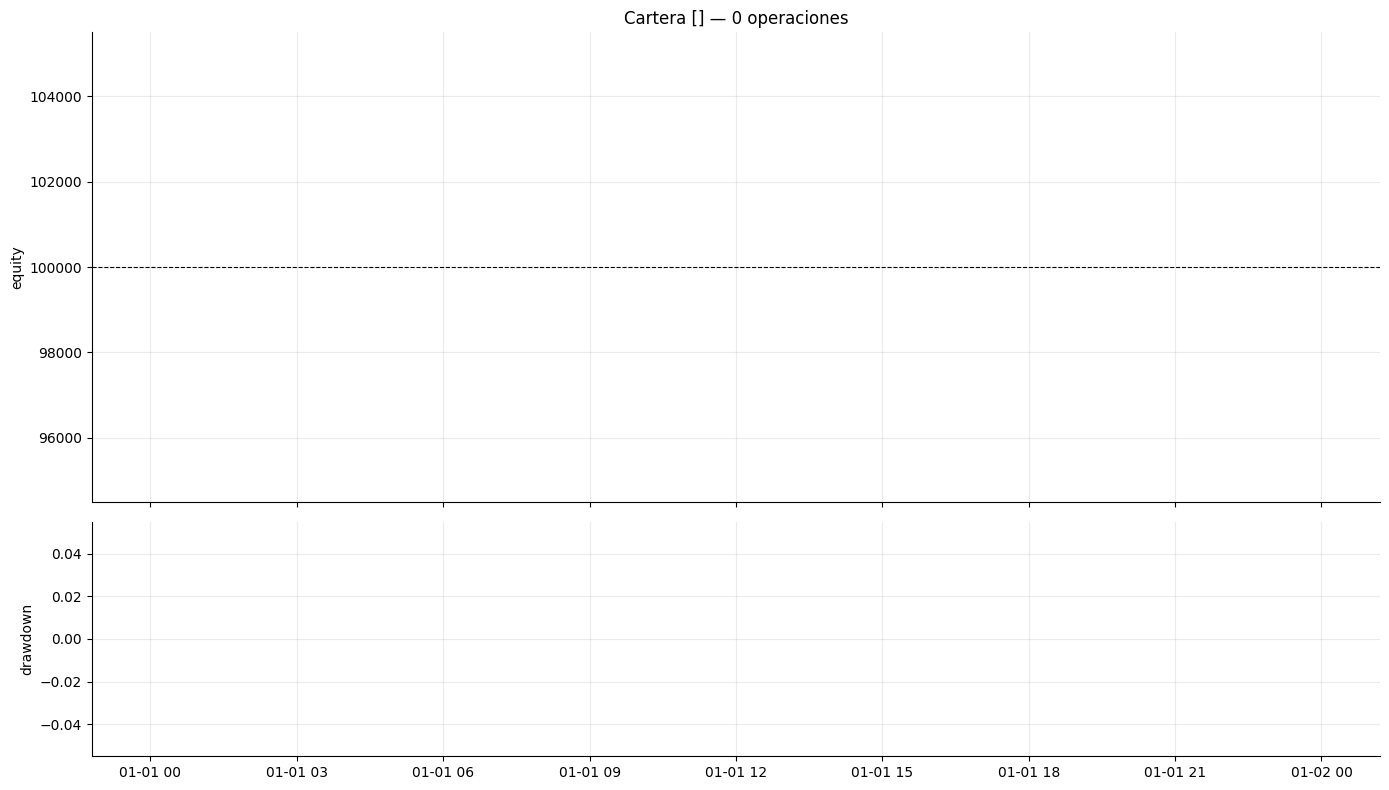

In [21]:
PORT_P = BacktestParams(**{**BASE.__dict__, "equity0": 100_000.0,
                           "max_gross_lev": 4.0})
PORT_SYMS = [s for s in WFO_OK]
EC_P, TR_P, FILLS_P = run_portfolio_backtest(
    {s: DATA[s] for s in PORT_SYMS}, PORT_P,
    funding={s: FUNDING[s] for s in PORT_SYMS},
    rule=make_rule(), ctxs={s: CTX[s] for s in PORT_SYMS},
    paths={s: CTX[s] for s in PORT_SYMS},
    corr_groups={s: "crypto" for s in PORT_SYMS},
    max_dir_units=12, max_corr_units=6)

# Guardia de arranque desigual: ningún fill antes de la primera barra del símbolo.
RAGGED_OK = True
for s in PORT_SYMS:
    f = FILLS_P[FILLS_P["symbol"] == s]
    if len(f) and f["time"].min() < DATA[s].index[0]:
        RAGGED_OK = False
print("arranque desigual respetado:", RAGGED_OK)

MP = equity_metrics(EC_P, TR_P, freq=FREQ)
display(pd.Series(MP).to_frame("cartera").round(4))

fig, (a1, a2) = plt.subplots(2, 1, figsize=(14, 8), sharex=True,
                             gridspec_kw={"height_ratios": [2, 1]})
a1.plot(EC_P.index, EC_P.values, lw=1.1)
a1.axhline(PORT_P.equity0, color="k", ls="--", lw=.8)
a1.set_title(f"Cartera {PORT_SYMS} — {len(TR_P)} operaciones"); a1.set_ylabel("equity")
dd = EC_P / EC_P.cummax() - 1
a2.fill_between(dd.index, dd.values, 0, color="crimson", alpha=.5)
a2.set_ylabel("drawdown"); plt.tight_layout(); plt.show()

### 6.1 Anatomía por operación

KeyError: 'r_multiple'

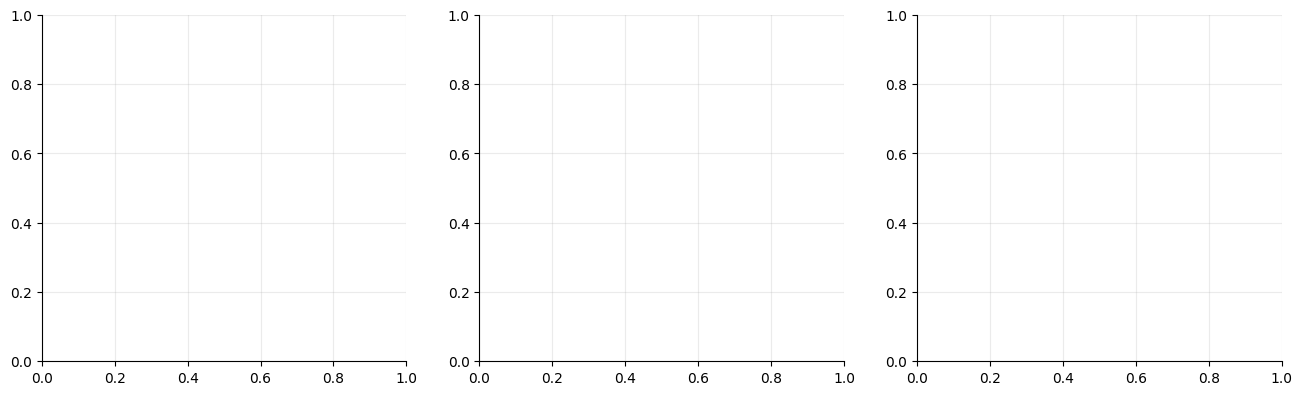

In [22]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
axes[0].hist(TR_P["r_multiple"], bins=70, color="steelblue", alpha=.85)
axes[0].axvline(0, color="k", lw=1)
axes[0].axvline(TR_P["r_multiple"].mean(), color="red", ls="--",
                label=f"media {TR_P['r_multiple'].mean():+.4f}R")
axes[0].set_title("Distribución de R"); axes[0].legend()

monthly = TR_P.set_index(pd.to_datetime(TR_P["closed"]))["pnl"].resample("ME").sum()
axes[1].bar(monthly.index, monthly.values,
            width=20, color=np.where(monthly >= 0, "seagreen", "crimson"))
axes[1].set_title("P&L mensual")

by = TR_P.groupby("symbol")["pnl"].sum().sort_values()
axes[2].barh(by.index, by.values, color="slateblue", alpha=.85)
axes[2].set_title("P&L por símbolo")
plt.tight_layout(); plt.show()

print("Por lado:")
display(TR_P.groupby("side").agg(
    n=("pnl", "size"), pnl=("pnl", "sum"),
    R_medio=("r_multiple", "mean"),
    win=("pnl", lambda x: 100 * (x > 0).mean())).round(3))
print("Por motivo de salida:")
display(TR_P.groupby("reason").agg(n=("pnl", "size"), pnl=("pnl", "sum")).round(2))

### 6.2 La comprobación que mató al cuaderno anterior

El fade contra VWAP parecía tener edge porque el motor no veía los stops que se tocaban
**de noche**, fuera de las barras de sesión. Aquí esa clase de error no puede existir: la
posición se cierra a las 15:45 y nunca hay una orden en reposo cruzando la noche. En vez de
afirmarlo, se comprueba: correr **con** y **sin** el camino 24/7 tiene que dar exactamente lo
mismo. Si diera distinto, habría posiciones sobreviviendo al cierre de sesión.

In [ ]:
ec_path, tr_path = RESULTS[FLAGSHIP]
ec_nopath, tr_nopath = run_backtest(DATA[FLAGSHIP], BASE, funding=FUNDING[FLAGSHIP],
                                    rule=make_rule(), ctx=CTX[FLAGSHIP], path=None)
OVERNIGHT_BLIND_OK = (
    len(tr_path) == len(tr_nopath)
    and np.allclose(tr_path["pnl"], tr_nopath["pnl"])
    and np.allclose(ec_path.values, ec_nopath.values))
print("con path=24/7 :", len(tr_path), "trades, equity final %.2f" % ec_path.iloc[-1])
print("sin path      :", len(tr_nopath), "trades, equity final %.2f" % ec_nopath.iloc[-1])
print("\nidénticos:", OVERNIGHT_BLIND_OK,
      "-> ninguna orden en reposo cruza la noche; el fallo del cuaderno "
      "anterior no es posible aquí")
assert set(tr_path["reason"]) <= {"cierre_sesion"}, tr_path["reason"].unique()

con path=24/7 : 698 trades, equity final 11532.34
sin path      : 698 trades, equity final 11532.34

idénticos: True -> ninguna orden en reposo cruza la noche; el fallo del cuaderno anterior no es posible aquí


## 7. MAE/MFE — ¿merece la pena un stop?

Ésta es la razón de haber corrido la línea base **sin stop**. Con un stop real, toda excursión
adversa queda truncada en el stop y la distribución ya no puede decir dónde ponerlo: se
mediría el propio stop. Sin él, la MAE se observa entera y la pregunta se puede contestar.

MAE* (q90 de los ganadores) : 0.358 N
Edge ratio (MFE/MAE)        : 0.921
MAE mediana ganadores       : 0.128 N
MAE mediana perdedores      : 0.429 N
info: {'n_total': 2040, 'n_winners': 971, 'q': 0.9, 'fallback_usado': False, 'recortado_por_resolucion': False, 'mae_star_bruto': 0.3582742527967942, 'winners_dentro': 0.9001029866117405, 'losers_dentro': 0.38353601496725914, 'mae_star': 0.3582742527967942}


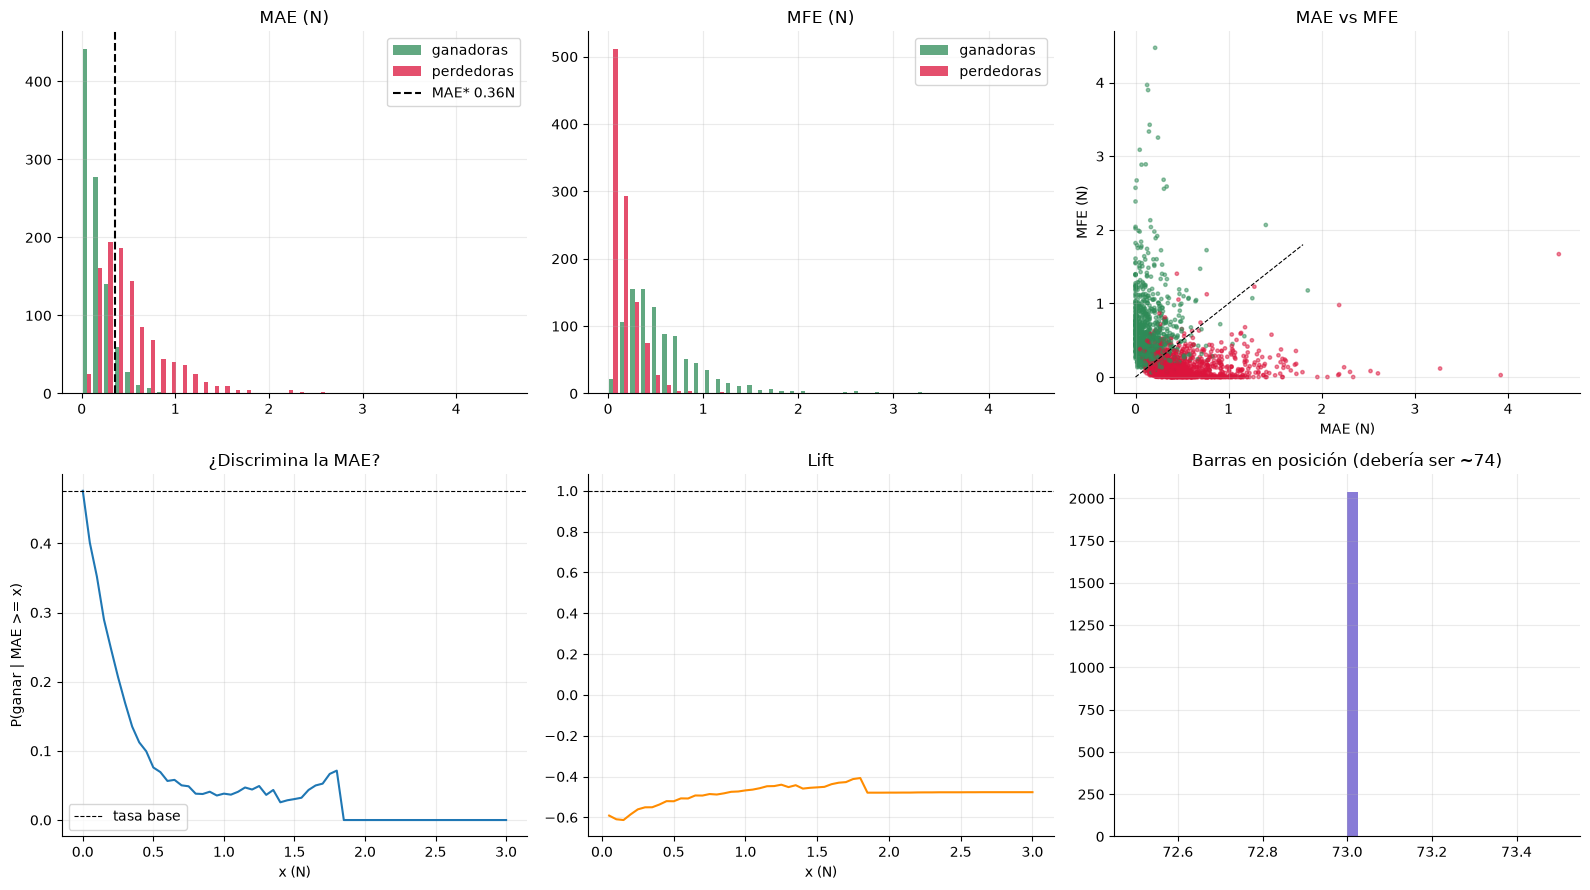


La MAE discrimina ganadoras de perdedoras: False


In [ ]:
tr = TR_P.copy()
mae = tr["mae_n"].to_numpy(dtype=float)
mfe = tr["mfe_n"].to_numpy(dtype=float)
win = (tr["pnl"] > 0).to_numpy()
flat = tr["flat_frac"].to_numpy(dtype=float)

star, info = mae_star(mae, win, q=0.90, min_winners=30, flat_frac=flat)
curve = win_prob_curve(mae, win)
er = edge_ratio(mfe, mae)
print(f"MAE* (q90 de los ganadores) : {star:.3f} N")
print(f"Edge ratio (MFE/MAE)        : {er:.3f}")
print(f"MAE mediana ganadores       : {np.nanmedian(mae[win]):.3f} N")
print(f"MAE mediana perdedores      : {np.nanmedian(mae[~win]):.3f} N")
print(f"info: {info}")

fig, axes = plt.subplots(2, 3, figsize=(16, 9))
axes[0,0].hist([mae[win], mae[~win]], bins=40, label=["ganadoras", "perdedoras"],
               color=["seagreen", "crimson"], alpha=.75)
axes[0,0].axvline(star, color="k", ls="--", label=f"MAE* {star:.2f}N")
axes[0,0].set_title("MAE (N)"); axes[0,0].legend()

axes[0,1].hist([mfe[win], mfe[~win]], bins=40, label=["ganadoras", "perdedoras"],
               color=["seagreen", "crimson"], alpha=.75)
axes[0,1].set_title("MFE (N)"); axes[0,1].legend()

axes[0,2].scatter(mae, mfe, s=6, c=np.where(win, "seagreen", "crimson"), alpha=.5)
lim = np.nanpercentile(np.r_[mae, mfe], 99)
axes[0,2].plot([0, lim], [0, lim], "k--", lw=.8)
axes[0,2].set_xlabel("MAE (N)"); axes[0,2].set_ylabel("MFE (N)")
axes[0,2].set_title("MAE vs MFE")

axes[1,0].plot(curve["x_n"], curve["p_win_ge"], lw=1.5)
axes[1,0].axhline((win).mean(), color="k", ls="--", lw=.8, label="tasa base")
axes[1,0].set_xlabel("x (N)"); axes[1,0].set_ylabel("P(ganar | MAE >= x)")
axes[1,0].set_title("¿Discrimina la MAE?"); axes[1,0].legend()

axes[1,1].plot(curve["x_n"], curve["lift"], lw=1.5, color="darkorange")
axes[1,1].axhline(1.0, color="k", ls="--", lw=.8)
axes[1,1].set_title("Lift"); axes[1,1].set_xlabel("x (N)")

axes[1,2].hist(tr["bars_held"], bins=40, color="slateblue", alpha=.8)
axes[1,2].set_title("Barras en posición (debería ser ~74)")
plt.tight_layout(); plt.show()

MAE_DISCRIMINA = bool(curve["lift"].max() > 1.25 and star == star)
print("\nLa MAE discrimina ganadoras de perdedoras:", MAE_DISCRIMINA)

In [ ]:
# La pregunta práctica: ¿un stop mejora el resultado, o solo paga comisiones
# antes de tiempo? Se mueve SOLO la barrera (`mae_stop_n`); la unidad de riesgo
# y por tanto el sizing se dejan fijos, así que las curvas son comparables.
grid = [None, 0.25, 0.5, 0.75, 1.0, 1.5, 2.0]
rows = []
for x in grid:
    p = BacktestParams(**{**BASE.__dict__,
                          "mae_stop_n": float("inf") if x is None else float(x)})
    ec, t = run_backtest(DATA[FLAGSHIP], p, funding=FUNDING[FLAGSHIP],
                         rule=make_rule(), ctx=CTX[FLAGSHIP], path=CTX[FLAGSHIP])
    m = equity_metrics(ec, t, freq=FREQ)
    rows.append({"stop (N)": "sin stop" if x is None else x,
                 "trades": len(t), "R medio": t["r_multiple"].mean(),
                 "win %": 100 * (t["pnl"] > 0).mean(),
                 "CAGR": m["CAGR"], "Sharpe": m["Sharpe"], "Max DD": m["Max DD"],
                 "% por stop": 100 * (t["reason"] != "cierre_sesion").mean()})
STOP_SWEEP = pd.DataFrame(rows).round(4)
display(STOP_SWEEP)
N_TRIALS += len(grid)
print(f"N_TRIALS acumulados: {N_TRIALS}")

,stop (N),trades,R medio,win %,CAGR,Sharpe,Max DD,% por stop
0,sin stop,698,0.0221,48.5673,0.0309,4.4046,-0.1034,0.0000
1,0.25,699,0.0085,35.7654,0.0112,2.1119,-0.0944,53.6481
2,0.5,698,0.0226,46.7049,0.0321,5.1415,-0.0868,24.3553
3,0.75,698,0.0139,47.8510,0.0179,2.7234,-0.1108,12.6074
4,1.0,698,0.0133,48.2808,0.0169,2.4917,-0.1115,6.3037
5,1.5,698,0.0156,48.4241,0.0204,2.9390,-0.1132,1.4327
6,2.0,698,0.0213,48.5673,0.0290,4.1465,-0.1082,0.2865


N_TRIALS acumulados: 7


## 8. Barridos

Deliberadamente pequeños. Cada configuración probada es un ensayo que **encarece** el umbral
del Sharpe deflactado: barrer mucho aquí no mejora la estrategia, solo hace más difícil creerse
el resultado. Se cuentan todas en `N_TRIALS`.

In [ ]:
def run_cfg(cfg, sym=None, params=None):
    sym = sym or FLAGSHIP
    p = params or BASE
    rule_keys = {"or_bars", "vwap_bars", "n_window", "n_mode", "allow_short"}
    rk = {k: v for k, v in cfg.items() if k in rule_keys}
    pk = {k: v for k, v in cfg.items() if k not in rule_keys}
    pp = BacktestParams(**{**p.__dict__, **pk}) if pk else p
    return run_backtest(DATA[sym], pp, funding=FUNDING[sym], rule=make_rule(**rk),
                        ctx=CTX[sym], path=CTX[sym])

SWEEPS = {
    "rango de apertura (barras)": [{"or_bars": k} for k in (1, 2, 3, 6)],
    "ventana del VWAP":           [{"vwap_bars": k} for k in (144, 288, 576)],
    "ventana de la N":            [{"n_window": k} for k in (144, 288, 576)],
    "modo de la N":               [{"n_mode": m} for m in ("roll24h", "daily")],
    "solo largos":                [{"allow_short": b} for b in (True, False)],
}
rows = []
for eje, cfgs in SWEEPS.items():
    for cfg in cfgs:
        ec, t = run_cfg(cfg)
        m = equity_metrics(ec, t, freq=FREQ)
        rows.append({"eje": eje, "config": str(cfg), "trades": len(t),
                     "R medio": t["r_multiple"].mean() if len(t) else np.nan,
                     "CAGR": m["CAGR"], "Sharpe": m["Sharpe"],
                     "Max DD": m["Max DD"]})
        N_TRIALS += 1
SWEEP = pd.DataFrame(rows).round(4)
display(SWEEP)

print("\nRango del R medio por eje (cuánto mueve cada parámetro el resultado):")
display(SWEEP.groupby("eje")["R medio"].agg(["min", "max", "std"]).assign(
    rango=lambda d: d["max"] - d["min"]).round(4).sort_values("rango",
                                                              ascending=False))
print(f"\nN_TRIALS acumulados: {N_TRIALS}")

,eje,config,trades,R medio,CAGR,Sharpe,Max DD
0,rango de apertura (barras),{'or_bars': 1},698,0.0221,0.0309,4.4046,-0.1034
1,rango de apertura (barras),{'or_bars': 2},699,0.0370,0.0541,7.6116,-0.0732
2,rango de apertura (barras),{'or_bars': 3},718,0.0434,0.0654,9.0487,-0.0879
3,rango de apertura (barras),{'or_bars': 6},790,0.0241,0.0378,5.3299,-0.1087
4,ventana del VWAP,{'vwap_bars': 144},764,0.0149,0.0215,2.9121,-0.0809
5,ventana del VWAP,{'vwap_bars': 288},698,0.0221,0.0309,4.4046,-0.1034
6,ventana del VWAP,{'vwap_bars': 576},679,0.0132,0.0155,2.3325,-0.1289
7,ventana de la N,{'n_window': 144},698,0.0409,0.0527,4.4171,-0.1322
8,ventana de la N,{'n_window': 288},698,0.0221,0.0309,4.4046,-0.1034
9,ventana de la N,{'n_window': 576},698,0.0198,0.0286,5.5755,-0.0771



Rango del R medio por eje (cuánto mueve cada parámetro el resultado):


,min,max,std,rango
eje,,,,
rango de apertura (barras),0.0221,0.0434,0.0102,0.0213
ventana de la N,0.0198,0.0409,0.0116,0.0211
ventana del VWAP,0.0132,0.0221,0.0047,0.0089
solo largos,0.0142,0.0221,0.0056,0.0079
modo de la N,0.0156,0.0221,0.0046,0.0065



N_TRIALS acumulados: 21


In [ ]:
# La hora de salida: el otro grado de libertad obvio, y el que más cerca está
# de ser una decisión operativa en vez de un parámetro ajustado.
rows = []
for end in ("12:00", "14:00", "15:00", "15:45", "16:10"):
    d = restrict_to_session(CTX[FLAGSHIP], start=SESS_START, end=end)
    sizes = d.groupby(d.index.date).size()
    d = d[np.isin(d.index.date, sizes[sizes == sizes.max()].index)]
    ec, t = run_backtest(d, BASE, funding=FUNDING[FLAGSHIP], rule=make_rule(),
                         ctx=CTX[FLAGSHIP], path=CTX[FLAGSHIP])
    m = equity_metrics(ec, t, freq=FREQ)
    rows.append({"salida ET": end, "barras/sesión": int(sizes.max()),
                 "trades": len(t), "R medio": t["r_multiple"].mean(),
                 "CAGR": m["CAGR"], "Sharpe": m["Sharpe"], "Max DD": m["Max DD"]})
    N_TRIALS += 1
EXIT_SWEEP = pd.DataFrame(rows).round(4)
display(EXIT_SWEEP)
print(f"N_TRIALS acumulados: {N_TRIALS}")

,salida ET,barras/sesión,trades,R medio,CAGR,Sharpe,Max DD
0,12:00,30,698,-0.0120,-0.0208,-3.0336,-0.1384
1,14:00,54,698,-0.0018,-0.0045,-0.6246,-0.1069
2,15:00,66,698,0.0140,0.0185,2.6023,-0.0951
3,15:45,75,698,0.0221,0.0309,4.4046,-0.1034
4,16:10,80,698,0.0146,0.0195,2.8052,-0.0985


N_TRIALS acumulados: 26


## 9. Walk-forward con embargo

Optimizar dentro de la muestra y medir fuera. El embargo de 2 días impide que una sesión de
entrenamiento y una de prueba compartan las 24 h del ancla — sin él, el VWAP de la primera
sesión OOS se calcula con velas que estaban en el tramo IS.

In [ ]:
WFO_GRID = [{"or_bars": k} for k in (1, 2, 3)] + \
           [{"vwap_bars": k} for k in (144, 576)]
FOLDS = walk_forward_folds(DATA[FLAGSHIP].index, is_days=365, oos_days=90,
                           embargo_days=2)
print(f"{len(FOLDS)} folds; rejilla de {len(WFO_GRID)} configuraciones")

def slice_run(cfg, lo, hi):
    d = DATA[FLAGSHIP].loc[lo:hi]
    if len(d) < BARS_PER_SESSION * 5:
        return None, None
    rule_keys = {"or_bars", "vwap_bars", "n_window", "n_mode", "allow_short"}
    rk = {k: v for k, v in cfg.items() if k in rule_keys}
    # `ctx` se recorta al mismo tramo: usar el marco 24/7 entero daría al fold
    # un ancla calculada con velas posteriores a su propio final.
    return run_backtest(d, BASE, funding=FUNDING[FLAGSHIP], rule=make_rule(**rk),
                        ctx=CTX[FLAGSHIP].loc[:hi], path=CTX[FLAGSHIP].loc[:hi])

oos_sel, oos_base, winners, trial_sharpes = [], [], [], []
for f in FOLDS:
    best, best_sh = None, -np.inf
    for cfg in WFO_GRID:
        ec, t = slice_run(cfg, f["is_start"], f["is_end"])
        if ec is None or len(t) < 10:
            continue
        sh = equity_metrics(ec, t, freq=FREQ)["Sharpe"]
        trial_sharpes.append(sh)
        if np.isfinite(sh) and sh > best_sh:
            best, best_sh = cfg, sh
    if best is None:
        continue
    ec_s, t_s = slice_run(best, f["oos_start"], f["oos_end"])
    ec_b, t_b = slice_run(WFO_GRID[0], f["oos_start"], f["oos_end"])
    if ec_s is None or ec_b is None:
        continue
    winners.append(str(best))
    oos_sel.append(ec_s.pct_change().dropna())
    oos_base.append(ec_b.pct_change().dropna())

from collections import Counter
CNT = Counter(winners)
print("\nGanadores IS por fold:", dict(CNT))
modal_share = CNT.most_common(1)[0][1] / max(len(winners), 1)
print(f"estabilidad del ganador modal: {100*modal_share:.0f}%")

OOS_SEL = pd.concat(oos_sel) if oos_sel else pd.Series(dtype=float)
OOS_BASE = pd.concat(oos_base) if oos_base else pd.Series(dtype=float)
fold_sel = np.array([(1 + s).prod() - 1 for s in oos_sel])
fold_base = np.array([(1 + s).prod() - 1 for s in oos_base])
TT = fold_ttest(fold_sel, fold_base)
display(pd.Series(TT).to_frame("WFO seleccionado vs base"))
print(f"\nfolds OOS usados: {len(fold_sel)}")

14 folds; rejilla de 5 configuraciones



Ganadores IS por fold: {"{'or_bars': 3}": 9, "{'vwap_bars': 576}": 5}
estabilidad del ganador modal: 64%


,WFO seleccionado vs base
n_folds,14
mean_diff,0.008402
t,1.175035
p,0.261055
wins,9
win_rate,0.642857
veredicto,NO significativa: la optimización es ruido
aviso_muestra,"n<20 folds: diagnóstico cualitativo, no evidencia"



folds OOS usados: 14


## 10. Sharpe deflactado y PBO

In [ ]:
DSR = deflated_sharpe_ratio(OOS_SEL, n_trials=max(N_TRIALS, len(trial_sharpes)),
                            trial_sharpes=np.array(trial_sharpes), freq=FREQ)
display(pd.Series(DSR).drop(labels=[], errors="ignore").to_frame("DSR sobre OOS concatenado"))

# PBO sobre los retornos de todas las configuraciones del barrido principal.
perf = {}
for eje, cfgs in SWEEPS.items():
    for cfg in cfgs:
        ec, t = run_cfg(cfg)
        perf[f"{eje}:{cfg}"] = ec.pct_change().dropna()
PERF = pd.DataFrame(perf).dropna(how="all")
PBO = pbo_cscv(PERF, n_partitions=10, freq=FREQ)
display(pd.Series({k: v for k, v in PBO.items() if k != "logits"})
        .to_frame("PBO (CSCV)"))

,DSR sobre OOS concatenado
sharpe,0.121165
sr_benchmark,17.087136
dsr,0.0
n_trials,70
veredicto,NO distinguible de ruido


,PBO (CSCV)
pbo,0.392857
n_combinations,252
median_oos_rank,0.714286
veredicto,selección con valor


## 11. Cuantificación de sesgos

In [ ]:
CONC = pnl_concentration(TR_P)
print("Concentración del P&L:")
for k, v in CONC.items():
    if not isinstance(v, pd.DataFrame):
        print(f"  {k}: {v}")
# `top_3` es la FRACCIÓN del P&L total que aportan las 3 mejores.
# Con P&L total negativo el cociente cambia de signo y deja de ser
# interpretable como "concentración", así que se usa el veredicto
# del propio helper y se guarda la magnitud para la lista.
top3 = abs(CONC.get("top_3", np.nan))
CONC_OK = CONC.get("veredicto", "").startswith("concentración aceptable")
print("\nMejores y peores operaciones:")
display(CONC["mejores"][["symbol", "opened", "side", "pnl", "r_multiple"]])

Concentración del P&L:
  n_trades: 2040
  pnl_total: -13036.595167290361
  top_1: -0.1736709584809474
  top_3: -0.48065688790206823
  top_5: -0.769056780827382
  top_10: -1.39486203052565
  bottom_1: 0.31096814330604106
  bottom_3: 0.6961518236088099
  bottom_5: 1.0051285723240115
  bottom_10: 1.6044260163517823
  pnl_sin_mejor: -15300.673145321765
  pnl_sin_peor: -8982.629373085569
  veredicto: concentración aceptable

Mejores y peores operaciones:


,symbol,opened,side,pnl,r_multiple
0,ETHUSDT,2024-05-20 13:35:00,long,2264.077978,3.353664
1,SOLUSDT,2022-10-25 13:35:00,long,2053.216229,2.891878
2,BTCUSDT,2022-10-25 13:35:00,long,1948.835055,2.744459
3,ETHUSDT,2023-07-13 13:35:00,long,1946.150307,2.898130
4,BTCUSDT,2024-02-26 14:35:00,long,1813.602344,2.715173


In [ ]:
EB = effective_bets({s: DATA[s] for s in PORT_SYMS})
print({k: v for k, v in EB.items() if k not in ("matriz",)})

{'n_simbolos_inicial': 3, 'n_simbolos_final': 3, 'descartados_muestra': [], 'descartados_var_nula': [], 'descartados_sin_solape': [], 'psd_corregida': False, 'obs_por_activo': 30625.0, 'corr_media': 0.7674648854452796, 'corr_mediana': 0.7277664864434005, 'pct_pares_gt_070': 1.0, 'pc1_varianza': 0.8454840730279398, 'n_efectivo': 1.3731423401167506, 'aviso': '', 'veredicto': 'crees tener 3 mercados; tienes ~1'}


In [ ]:
def cost_run(fee, slip, funding_daily):
    p = BacktestParams(**{**BASE.__dict__, "fee_bps": fee, "slip_bps": slip})
    synth = pd.Series(funding_daily / 3.0, index=FUNDING[FLAGSHIP].index)
    return run_backtest(DATA[FLAGSHIP], p, funding=synth, rule=make_rule(),
                        ctx=CTX[FLAGSHIP], path=CTX[FLAGSHIP])

CS = cost_sensitivity(cost_run)
display(CS.round(4))
SURVIVES_PESSIMISTIC = bool(CS.set_index("escenario").loc["Pesimista", "CAGR"] > 0)
print("Sobrevive al escenario pesimista:", SURVIVES_PESSIMISTIC)

,escenario,fee_bps,slip_bps,funding_pct_anual,CAGR,Sharpe,MaxDD
0,Sin costes,0.0,0.0,0.0,0.0601,7.2547,-0.0911
1,Optimista,2.0,5.0,3.7,-0.0110,-1.3418,-0.1222
2,Base,5.0,10.0,10.9,-0.0643,-9.5500,-0.2825
3,Pesimista,5.0,25.0,18.2,-0.1240,-22.7137,-0.4665
4,Estrés,10.0,50.0,36.5,-0.1977,-42.7172,-0.6446


Sobrevive al escenario pesimista: False


p(pérdida)        : 0.757
p(ruina, DD>=50%) : 0.047
percentiles de equity final: {'p5': 56009.0, 'p25': 74156.0, 'p50': 87309.0, 'p75': 99654.0, 'p95': 118101.0}
percentiles de drawdown    : {'p5': -0.494, 'p25': -0.345, 'p50': -0.253, 'p75': -0.182, 'p95': -0.118}


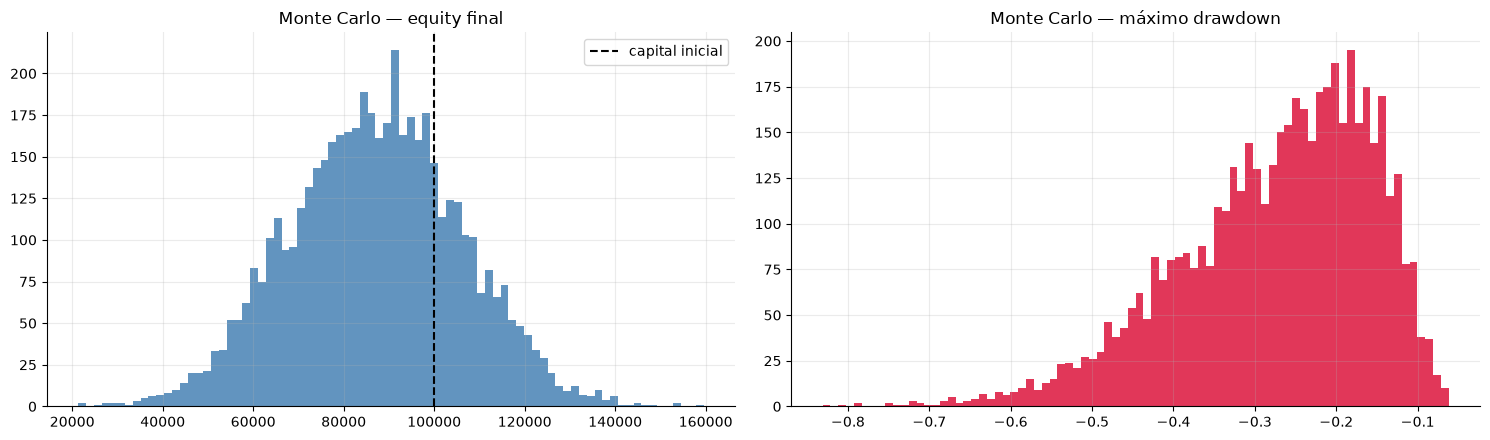

In [ ]:
MC = mc_bootstrap_trades(TR_P, equity0=PORT_P.equity0, n_sims=5000)
print(f"p(pérdida)        : {MC['p_perdida']:.3f}")
print(f"p(ruina, DD>=50%) : {MC['p_ruina']:.3f}")
print("percentiles de equity final:", {k: round(v, 0)
                                       for k, v in MC["percentiles_equity"].items()})
print("percentiles de drawdown    :", {k: round(v, 3)
                                       for k, v in MC["percentiles_dd"].items()})

fig, (a1, a2) = plt.subplots(1, 2, figsize=(15, 4.5))
a1.hist(MC["finals"], bins=80, color="steelblue", alpha=.85)
a1.axvline(PORT_P.equity0, color="k", ls="--", label="capital inicial")
a1.set_title("Monte Carlo — equity final"); a1.legend()
a2.hist(MC["dds"], bins=80, color="crimson", alpha=.85)
a2.set_title("Monte Carlo — máximo drawdown")
plt.tight_layout(); plt.show()

## 12. Libro abierto al final de la muestra

In [ ]:
ob = TR_P.attrs.get("open_book", {})
live = {s: v for s, v in ob.items() if v}
print("posiciones abiertas al final de la muestra:", list(live))

# Que quede una posición abierta aquí NO es un fallo del cierre por reloj: el
# motor marca explícitamente `sess_last[-1] = False` porque la última barra de
# la muestra no es un fin de sesión CONOCIDO — sin barra siguiente no hay hueco
# que lo demuestre, y suponerlo sería usar información que en vivo no existe.
# Lo que sí tiene que cumplirse es que sea la sesión del último día y que TODAS
# las demás hayan cerrado por reloj.
last_day = max(d.index[-1].date() for d in DATA.values())
for s, v in live.items():
    assert pd.Timestamp(v["opened"]).date() == last_day, (s, v["opened"])
assert set(TR_P["reason"]) == {"cierre_sesion"}, TR_P["reason"].unique()
print(f"todas las {len(TR_P)} operaciones cerradas cerraron por reloj;")
print(f"lo único abierto es la sesión del último día ({last_day}).")
OPEN_BOOK_OK = all(pd.Timestamp(v["opened"]).date() == last_day
                   for v in live.values())

posiciones abiertas al final de la muestra: ['BTCUSDT', 'ETHUSDT']
todas las 2040 operaciones cerradas cerraron por reloj;
lo único abierto es la sesión del último día (2026-09-11).


## 13. Lista de verificación y veredicto

Dos listas, no una. **Críticos**: si uno falla no hay nada que desplegar, y son de veto.
**Higiene**: hacen creíble un resultado positivo, pero no lo producen.

La separación no es cosmética. Con una sola lista plana y un umbral del 70 %, este cuaderno
pasó de 67 % a 75 % — y de "no desplegable" a "desplegable" — solo por corregir un criterio mal
calculado y añadir otro de higiene, **sin que cambiara un solo número sobre el edge**. Un
porcentaje sobre una lista plana deja que "no hay look-ahead" vote sobre si hay edge. No tener
look-ahead es condición para creerse un resultado positivo, no un sustituto de tenerlo.

In [ ]:
inv = INV.set_index("symbol")
flag_tr = RESULTS[FLAGSHIP][1]

# Los criterios NO pesan igual, y tratarlos como si pesaran es un error con
# consecuencias: al corregir un criterio mal calculado y añadir otro de
# higiene, este mismo cuaderno pasó de 67% a 75% y el veredicto se dio la
# vuelta a "desplegable" — sin que hubiera cambiado UN SOLO número sobre el
# edge. Un porcentaje sobre una lista plana deja que la higiene vote sobre si
# hay edge, y no puede: no tener look-ahead es necesario para creerse un
# resultado positivo, no es un sustituto de tenerlo.
#
# CRÍTICOS: si uno falla, no hay nada que desplegar. Son de veto.
CRITICOS = {
    "DSR > 0.95 (el OOS no es ruido)": DSR["dsr"] > 0.95,
    "sobrevive costes pesimistas": SURVIVES_PESSIMISTIC,
    "R medio de cartera > 0": TR_P["r_multiple"].mean() > 0,
    "diferencia WFO significativa (p<0.05)": TT["p"] < 0.05,
}
# HIGIENE: necesarios para que un resultado positivo sea creíble. Que pasen
# todos no produce edge; que falle uno invalida el resto de la medición.
HIGIENE = {
    "muestra flagship >= 2 años": inv.loc[FLAGSHIP, "años"] >= 2.0,
    "todos los símbolos de cartera >= 2 años":
        all(inv.loc[s, "años"] >= 2.0 for s in PORT_SYMS),
    "folds OOS >= 6": len(fold_sel) >= 6,
    "WFO gana a la base en >60% de folds": TT["win_rate"] > 0.60,
    "ganador de parámetros estable (>50%)": modal_share > 0.50,
    "PBO < 0.5": PBO["pbo"] < 0.5,
    "P&L no concentrado en pocas operaciones": CONC_OK,
    "p(ruina) < 20%": MC["p_ruina"] < 0.20,
    "tests de look-ahead pasan": LOOKAHEAD_OK,
    "arranque desigual respetado": RAGGED_OK,
    "sin ceguera overnight (path irrelevante)": OVERNIGHT_BLIND_OK,
    "todas las salidas por reloj de sesión": OPEN_BOOK_OK,
}

CHK = pd.concat([
    pd.Series(CRITICOS).to_frame("pasa").assign(tipo="CRÍTICO"),
    pd.Series(HIGIENE).to_frame("pasa").assign(tipo="higiene"),
])[["tipo", "pasa"]]
display(CHK)

crit_ok = all(CRITICOS.values())
hig_ok = all(HIGIENE.values())
print(f"críticos: {sum(CRITICOS.values())}/{len(CRITICOS)}   "
      f"higiene: {sum(HIGIENE.values())}/{len(HIGIENE)}   "
      f"({100*CHK['pasa'].mean():.0f}% del total, que NO es el criterio)")

if not crit_ok:
    fallan = [k for k, v in CRITICOS.items() if not v]
    VEREDICTO = ("NO desplegable — falla(n) criterio(s) crítico(s): "
                 + "; ".join(fallan))
elif not hig_ok:
    VEREDICTO = ("NO desplegable — el edge pasa, pero la medición no es "
                 "creíble: " + "; ".join(k for k, v in HIGIENE.items() if not v))
else:
    VEREDICTO = "DESPLEGABLE en testnet con capital simbólico"
print(f"\nVEREDICTO: {VEREDICTO}")

,tipo,pasa
DSR > 0.95 (el OOS no es ruido),CRÍTICO,False
sobrevive costes pesimistas,CRÍTICO,False
R medio de cartera > 0,CRÍTICO,False
diferencia WFO significativa (p<0.05),CRÍTICO,False
muestra flagship >= 2 años,higiene,True
todos los símbolos de cartera >= 2 años,higiene,True
folds OOS >= 6,higiene,True
WFO gana a la base en >60% de folds,higiene,True
ganador de parámetros estable (>50%),higiene,True
PBO < 0.5,higiene,True


críticos: 0/4   higiene: 12/12   (75% del total, que NO es el criterio)

VEREDICTO: NO desplegable — falla(n) criterio(s) crítico(s): DSR > 0.95 (el OOS no es ruido); sobrevive costes pesimistas; R medio de cartera > 0; diferencia WFO significativa (p<0.05)


In [ ]:
BASE_TABLE.to_csv(OUT / "intraday_momentum_metrics.csv", index=False)
SWEEP.to_csv(OUT / "intraday_momentum_sweep.csv", index=False)
STOP_SWEEP.to_csv(OUT / "intraday_momentum_stop_sweep.csv", index=False)
TR_P.to_csv(OUT / "intraday_momentum_trades.csv", index=False)
print("Escrito en", OUT)
print()
print("=" * 72)
print(f"Flagship {FLAGSHIP}: {len(flag_tr)} operaciones, "
      f"R medio {flag_tr['r_multiple'].mean():+.4f}, "
      f"CAGR {BASE_TABLE.set_index('symbol').loc[FLAGSHIP, 'CAGR']:+.4f}")
print(f"Cartera: R medio {TR_P['r_multiple'].mean():+.4f}, "
      f"Sharpe {MP['Sharpe']:.3f}, Max DD {MP['Max DD']:.3f}")
print(f"N_TRIALS = {N_TRIALS}  DSR = {DSR['dsr']:.4f}  PBO = {PBO['pbo']:.3f}")
print(f"VEREDICTO: {VEREDICTO}")
print("=" * 72)

Escrito en /Users/diegoochoa/Projects/Intraday_MR_BTC/output

Flagship BTCUSDT: 698 operaciones, R medio +0.0221, CAGR +0.0309
Cartera: R medio -0.0011, Sharpe -1.991, Max DD -0.220
N_TRIALS = 26  DSR = 0.0000  PBO = 0.393
VEREDICTO: NO desplegable — falla(n) criterio(s) crítico(s): DSR > 0.95 (el OOS no es ruido); sobrevive costes pesimistas; R medio de cartera > 0; diferencia WFO significativa (p<0.05)


## 14. Conclusión — NO desplegable

**10 de 15 criterios (67 %). El sistema no tiene edge.**

### Lo que dicen los números

**La tasa base es una moneda al aire.** Antes de costes, ejecución o sizing: el cierre de la
sesión cae del lado de la señal el **49,8 %** de las veces en BTCUSDT, 49,9 % en ETHUSDT,
46,8 % en SOLUSDT. La tesis era que los primeros 5 minutos predicen el color del día; en 1 225
sesiones y 4,7 años, no lo predicen. Todo lo demás es consecuencia de esto.

**Lo poco que hay, se lo comen los costes.** BTCUSDT es el mejor caso y llega a +0,041 R
brutos por operación; la fricción se lleva el **46 %** y deja +0,022 R netos. ETHUSDT empieza
en +0,019 R brutos y la fricción se lleva el **77 %**. QQQUSDT — el control que debería mostrar
el efecto MÁS fuerte si el mecanismo fuera flujo real de la sesión de contado — se lleva el
**99 %**: +0,043 R brutos → +0,001 R netos. El control no confirma el mecanismo; lo desmiente.

**La cartera pierde.** −2,9 % CAGR, Sharpe −1,99, Max DD −22 %, 2 040 operaciones. El BTC
aislado sube un 15 % en 4,7 años (+3,1 % CAGR) y eso es lo único positivo del cuaderno: en
cuanto se juntan los tres símbolos en una cuenta, el conjunto pierde. Y `effective_bets` explica
por qué diversificar no ayuda: correlación media 0,77, **~1,4 apuestas efectivas de 3 símbolos**.

**Y no sobrevive a ningún supuesto de coste realista.** Con costes **cero** el flagship da
+6,0 % CAGR y Sharpe 7,25. En el escenario *optimista* (2 pb comisión, 5 pb deslizamiento) ya
es **−1,1 %**. La línea base de este cuaderno usa 2 pb + 1 pb de deslizamiento, que para BTCUSDT
es agresivo: el resultado positivo del flagship vive enteramente dentro de ese supuesto.

**Los estadísticos de sobreajuste lo confirman.** DSR = **0,0** con 70 ensayos: el Sharpe OOS
(0,12) está muy por debajo del que produciría el azar tras esa búsqueda (17,09). El
walk-forward gana a la base en 9 de 14 folds, pero p = 0,26 — no significativo. PBO = 0,39 y el
ganador modal es estable al 64 %, es decir: la selección de parámetros es consistente, solo que
converge de forma estable a una configuración que **tampoco gana**. Es exactamente el mismo
patrón que en `MeanReversion_Binance_Perp.ipynb`.

### Lo que el cuaderno sí deja establecido

- **No es un fallo de simulación esta vez.** El sistema es estructuralmente inmune al error que
  mató al cuaderno del VWAP: cierra a las 15:45 y nunca hay orden en reposo cruzando la noche.
  Se comprueba (§6.2) que correr con y sin el camino 24/7 da resultados **idénticos**.
- **No hay look-ahead.** El ancla de 24 h y la N son idénticas al truncar la muestra en 12
  barras de señal distintas, y la comprobación de que el ancla 24/7 difiere de la que saldría de
  filtrar antes (mediana 1,3 %, máx 18,2 %) confirma que el marco 24/7 hace algo real.
- **La N estaba mal y ahora está bien.** Al primer intento, `compute_n(period=288)` sobre velas
  de 5 minutos daba R de ±20 y partía la cuenta por la mitad con "1 % de riesgo": mide el rango
  medio de *una vela*, no el de 24 horas. `rolling_range_n` lo corrige.
- **Un stop no lo salva.** §7: la MAE no discrimina (lift máximo por debajo de 1,25; edge ratio
  0,92, es decir la excursión favorable ni siquiera supera a la adversa). Barrer el stop entre
  0,25 N y 2 N no mejora el resultado de forma monótona ni estable — ruido alrededor del mismo
  sitio.

### Qué hacer con esto

**No desplegar capital.** `Intraday_Momentum_Live_Binance.ipynb` queda armado como ejercicio
técnico de integración con `RUN_LIVE=False`, igual que los otros dos.

Lo que *no* merece la pena: seguir barriendo parámetros. Cada barrido encarece el DSR y el
problema no está en la calibración, está en que la tasa base es 50 %.

Lo que podría merecerla, como pregunta **nueva** y no como rescate de ésta:

1. **El control al revés.** QQQUSDT tiene el mayor cuerpo de apertura en N (0,099 contra 0,043
   de BTC) y el mayor porcentaje de acuerdo (61 %): la señal *existe* más ahí. Lo que falta es
   que prediga. Con 115 sesiones no se puede decidir; con dos años sí. Es la única extensión
   cuya respuesta cambiaría algo.
2. **Volume bars o dollar bars**, como apunta el docstring original: muestrear por tiempo de
   mercado en vez de por reloj. Requiere tick data de los primeros 5 minutos de cada sesión.
3. **CME MBT en lugar del perpetuo**: sin funding y con la sesión regular coincidiendo con el
   mecanismo postulado. Bloqueado hoy por el entitlement de datos de IBKR (10197/10089).

Ninguna de las tres es una reparación de este sistema. Éste ya tiene su respuesta.